# SVD compression of high-resolution photographs

Two real photographs this time, both public domain and downloaded from Wikimedia Commons:

* **Grayscale** — Ansel Adams, *The Tetons and the Snake River* (1942), roughly 3000 × 4000 pixels.
* **Colour** — Hubble Space Telescope, *Pillars of Creation* (2014), roughly 6800 × 7000 pixels.

For each image we
1. report its true size (pixels, raw bytes, file size on disk),
2. compute the SVD (per colour channel for the colour image),
3. rebuild it from $k = 5, 20, 50, 100, 200$ singular components,
4. compare the reconstructions side by side, and
5. work out how many numbers / bytes the rank-$k$ version needs versus the original.

> **Use your own photo instead:** set `GRAY_SOURCE` or `COLOR_SOURCE` below to any file on your computer
> (a phone photo at 12 MP works very well). If the download fails, the notebook falls back to the sample images
> that ship with SciPy.

In [ ]:
import os, io, time, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
%matplotlib inline

# A local path or a URL. Wikimedia's Special:FilePath always redirects to the current full-resolution file.
GRAY_SOURCE  = "https://commons.wikimedia.org/wiki/Special:FilePath/Adams_The_Tetons_and_the_Snake_River.jpg"
COLOR_SOURCE = "https://commons.wikimedia.org/wiki/Special:FilePath/Pillars_of_creation_2014_HST_WFC3-UVIS_full-res_denoised.jpg"

# A full SVD of an N x N matrix costs ~N^3 operations and needs ~N^2 numbers for U and V.
# 7000 x 7000 takes minutes and several GB, so by default we shrink the longest side to MAX_SIDE first.
# Set MAX_SIDE = None to run on the full-resolution image (be patient, and have 8+ GB of RAM).
MAX_SIDE = 4000

ks = [5, 20, 50, 100, 200]

## 0. Helper functions

In [ ]:
def fetch_bytes(source):
    """Return the raw bytes of a local file or a URL."""
    if os.path.exists(source):
        with open(source, "rb") as f:
            return f.read()
    req = urllib.request.Request(source, headers={"User-Agent": "svd-class-demo/1.0"})
    with urllib.request.urlopen(req, timeout=120) as r:
        return r.read()

def load_image(source, mode, fallback):
    """Load as 'L' (grayscale) or 'RGB'. Returns (array, file_size_in_bytes, description)."""
    try:
        raw = fetch_bytes(source)
        im = Image.open(io.BytesIO(raw)).convert(mode)
        return np.asarray(im), len(raw), os.path.basename(source)
    except Exception as e:
        print(f"Could not load {source!r} ({e}).  Using SciPy sample image instead.")
        arr = fallback()
        return arr, arr.nbytes, "scipy sample image (uncompressed)"

def shrink(arr, max_side):
    if max_side is None or max(arr.shape[:2]) <= max_side:
        return arr
    im = Image.fromarray(arr)
    scale = max_side / max(arr.shape[:2])
    new_size = (round(arr.shape[1] * scale), round(arr.shape[0] * scale))     # PIL wants (width, height)
    return np.asarray(im.resize(new_size, Image.LANCZOS))

def human(nbytes):
    for unit in ("B", "KB", "MB", "GB"):
        if nbytes < 1024:
            return f"{nbytes:,.1f} {unit}"
        nbytes /= 1024
    return f"{nbytes:,.1f} TB"

def to_uint8(x):
    return np.clip(np.round(x), 0, 255).astype(np.uint8)

def rank_k(U, s, Vt, k):
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

def svd_storage(H, W, k, channels):
    """Numbers needed to store U_k (H x k), s_k (k) and Vt_k (k x W) for each channel."""
    return channels * k * (H + W + 1)

## Part 1 — Grayscale photograph

### 1.1 Load it and report the real size
A grayscale image stores **one byte per pixel** (0–255), so its raw size is simply height × width bytes.
The JPEG on disk is smaller because JPEG is already a (lossy) compression scheme.

Source           : Adams_The_Tetons_and_the_Snake_River.jpg
Resolution       : 2402 x 3000 pixels  =  7.2 megapixels
Raw size         : 7,206,000 numbers (1 byte each) = 6.9 MB
File size on disk: 1.8 MB  (JPEG, already compressed)


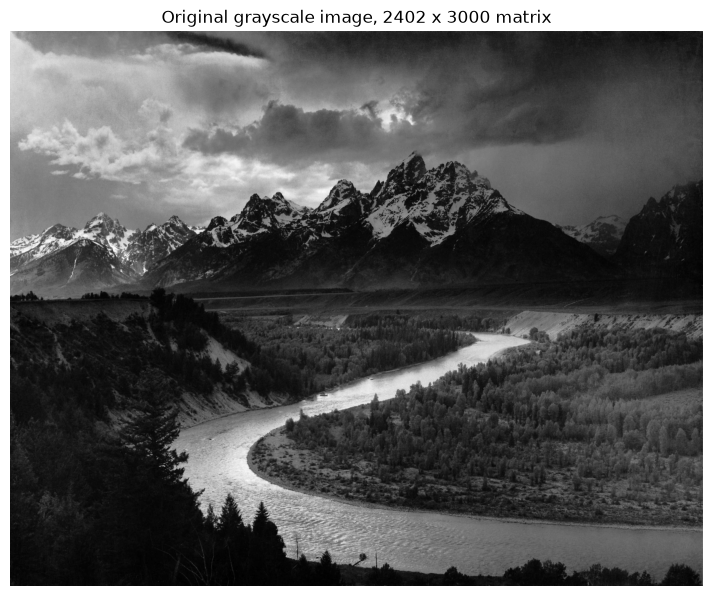

In [ ]:
import scipy.datasets
gray_full, gray_file_bytes, gray_name = load_image(GRAY_SOURCE, "L", scipy.datasets.ascent)

H0, W0 = gray_full.shape
print(f"Source           : {gray_name}")
print(f"Resolution       : {H0} x {W0} pixels  =  {H0*W0/1e6:.1f} megapixels")
print(f"Raw size         : {H0*W0:,} numbers (1 byte each) = {human(H0*W0)}")
print(f"File size on disk: {human(gray_file_bytes)}  (JPEG, already compressed)")

A = shrink(gray_full, MAX_SIDE).astype(float)
H, W = A.shape
if (H, W) != (H0, W0):
    print(f"\nWorking copy shrunk to {H} x {W} so the SVD runs in seconds.  Raw size of working copy: {human(H*W)}")

plt.figure(figsize=(9, 9 * H / W))
plt.imshow(A, cmap="gray", vmin=0, vmax=255); plt.axis("off")
plt.title(f"Original grayscale image, {H} x {W} matrix")
plt.show()

### 1.2 SVD of the whole $H \times W$ matrix

SVD took 2.4 s
U (2402, 2402)   s (2402,)   Vt (2402, 3000)
The matrix has rank at most min(H, W) = 2402, so there are 2402 singular values.
Largest sigma = 219,115   sigma_200 = 1,253   smallest = 2.53


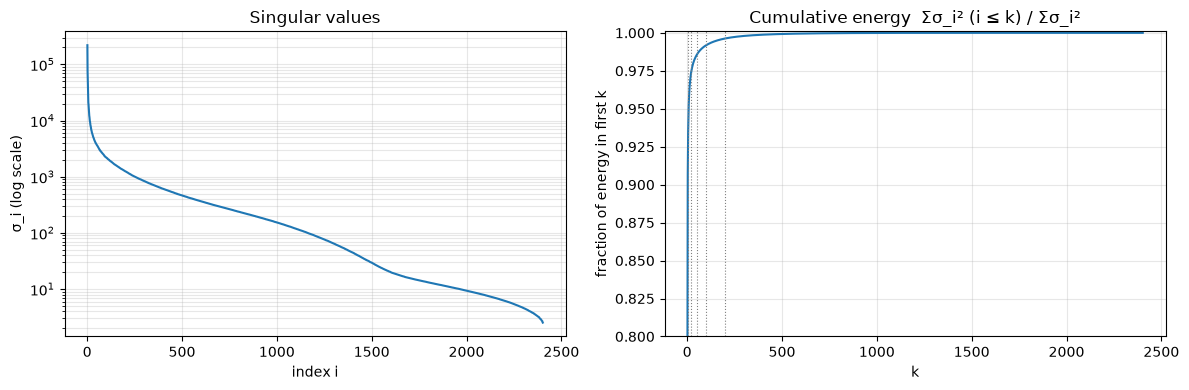

In [ ]:
t0 = time.time()
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print(f"SVD took {time.time()-t0:.1f} s")
print(f"U {U.shape}   s {s.shape}   Vt {Vt.shape}")
print(f"The matrix has rank at most min(H, W) = {min(H, W)}, so there are {len(s)} singular values.")
print(f"Largest sigma = {s[0]:,.0f}   sigma_200 = {s[199]:,.0f}   smallest = {s[-1]:.2f}")

energy = np.cumsum(s**2) / np.sum(s**2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.semilogy(np.arange(1, len(s)+1), s); ax1.set_xlabel("index i"); ax1.set_ylabel("σ_i (log scale)")
ax1.set_title("Singular values"); ax1.grid(True, which="both", alpha=0.3)
ax2.plot(np.arange(1, len(s)+1), energy); ax2.set_xlabel("k"); ax2.set_ylabel("fraction of energy in first k")
ax2.set_title("Cumulative energy  Σσ_i² (i ≤ k) / Σσ_i²"); ax2.grid(True, alpha=0.3); ax2.set_ylim(0.8, 1.001)
for k in ks: ax2.axvline(k, color="gray", ls=":", lw=0.8)
plt.tight_layout(); plt.show()

### 1.3 Reconstruct with $k = 5, 20, 50, 100, 200$ and compare sizes

To store a rank-$k$ approximation we keep $U_k$ ($H \times k$), $s_k$ ($k$) and $V_k^T$ ($k \times W$):
$\;k\,(H + W + 1)$ numbers in total, against $H \cdot W$ for the original.
Below we count both the numbers and the bytes (storing each number as a 32-bit float, 4 bytes).

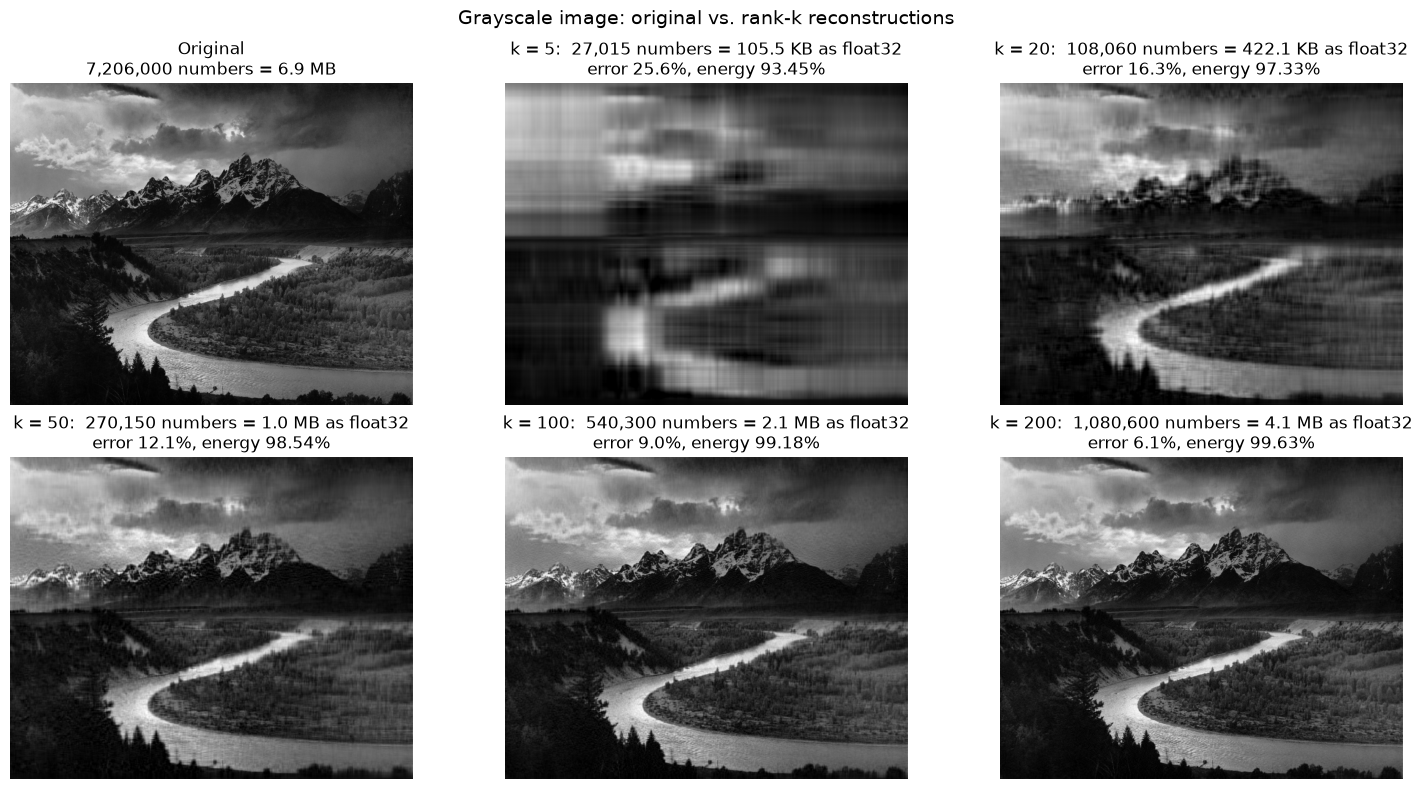

   k | rel. error |  energy |  numbers stored | bytes (float32) | orig/SVD
------------------------------------------------------------------------------
full |      0.00% | 100.00% |       7,206,000 |          6.9 MB |     1.00
   5 |     25.60% |  93.45% |          27,015 |        105.5 KB |    66.69x
  20 |     16.34% |  97.33% |         108,060 |        422.1 KB |    16.67x
  50 |     12.07% |  98.54% |         270,150 |          1.0 MB |     6.67x
 100 |      9.04% |  99.18% |         540,300 |          2.1 MB |     3.33x
 200 |      6.09% |  99.63% |       1,080,600 |          4.1 MB |     1.67x

Break-even: with float32 storage the SVD beats the 1-byte original only while 4k(H+W+1) < HW, i.e. k < 333.
Counting numbers rather than bytes, break-even is k = 1333.


In [ ]:
rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 10 * H / W))
axes = axes.ravel()
axes[0].imshow(A, cmap="gray", vmin=0, vmax=255); axes[0].set_title(f"Original\n{H*W:,} numbers = {human(H*W)}")
for ax, k in zip(axes[1:], ks):
    A_k = rank_k(U, s, Vt, k)
    err = np.linalg.norm(A - A_k) / np.linalg.norm(A)
    n = svd_storage(H, W, k, 1)
    rows.append((k, err, energy[k-1], n, n*4, (H*W)/(n*4)))
    ax.imshow(A_k, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k}:  {n:,} numbers = {human(n*4)} as float32\nerror {err:.1%}, energy {energy[k-1]:.2%}")
for ax in axes: ax.axis("off")
plt.suptitle("Grayscale image: original vs. rank-k reconstructions", fontsize=14)
plt.tight_layout(); plt.show()

print(f"{'k':>4} | {'rel. error':>10} | {'energy':>7} | {'numbers stored':>15} | {'bytes (float32)':>15} | {'orig/SVD':>8}")
print("-" * 78)
print(f"{'full':>4} | {0:>10.2%} | {1:>7.2%} | {H*W:>15,} | {human(H*W):>15} | {1:>8.2f}")
for k, err, en, n, b, ratio in rows:
    print(f"{k:>4} | {err:>10.2%} | {en:>7.2%} | {n:>15,} | {human(b):>15} | {ratio:>8.2f}x")
k_break = (H*W) // (H + W + 1)
print(f"\nBreak-even: with float32 storage the SVD beats the 1-byte original only while 4k(H+W+1) < HW, i.e. k < {k_break//4}.")
print(f"Counting numbers rather than bytes, break-even is k = {k_break}.")

### 1.4 Zoom in to see what is lost
Low-rank approximations blur fine texture and produce faint horizontal/vertical streaks — look at a crop.

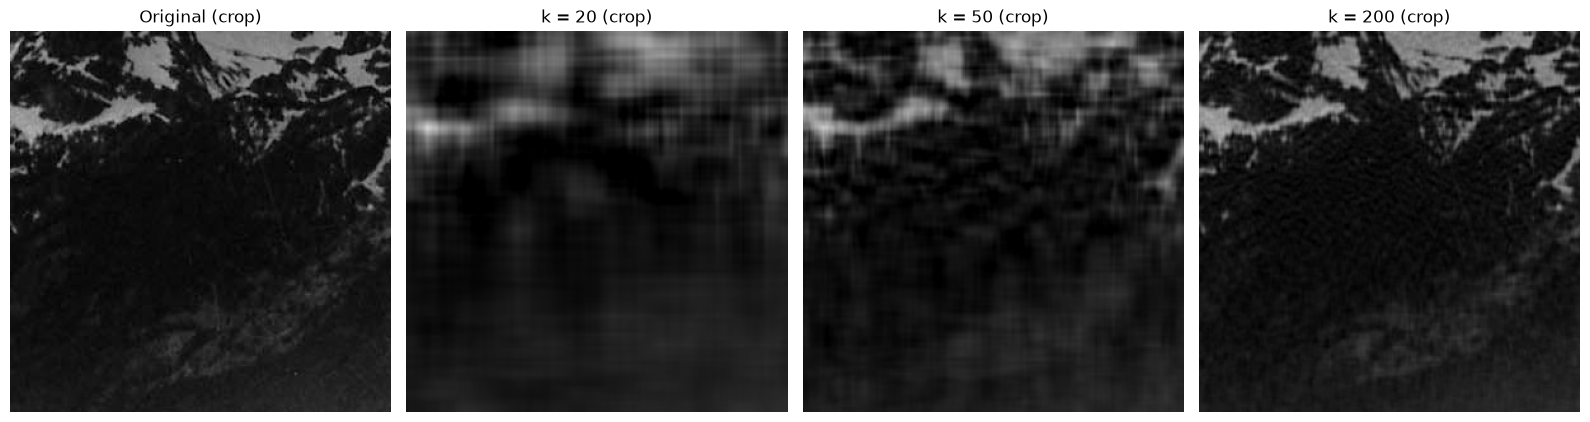

In [ ]:
r0, c0, size = H // 3, W // 3, min(300, H // 3, W // 3)      # crop position; change freely
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, k in zip(axes, [None, 20, 50, 200]):
    img = A if k is None else rank_k(U, s, Vt, k)
    ax.imshow(img[r0:r0+size, c0:c0+size], cmap="gray", vmin=0, vmax=255); ax.axis("off")
    ax.set_title("Original (crop)" if k is None else f"k = {k} (crop)")
plt.tight_layout(); plt.show()

## Part 2 — High-resolution colour photograph

### 2.1 Load it and report the real size
A colour image stores **three bytes per pixel** (R, G, B), so raw size = 3 × height × width bytes.

Source           : Pillars_of_creation_2014_HST_WFC3-UVIS_full-res_denoised.jpg
Resolution       : 7071 x 6780 x 3  =  47.9 megapixels
Raw size         : 143,824,140 numbers (1 byte each) = 137.2 MB
File size on disk: 44.8 MB  (JPEG, already compressed)

Working copy shrunk to 4000 x 3835 x 3.  Raw size of working copy: 43.9 MB


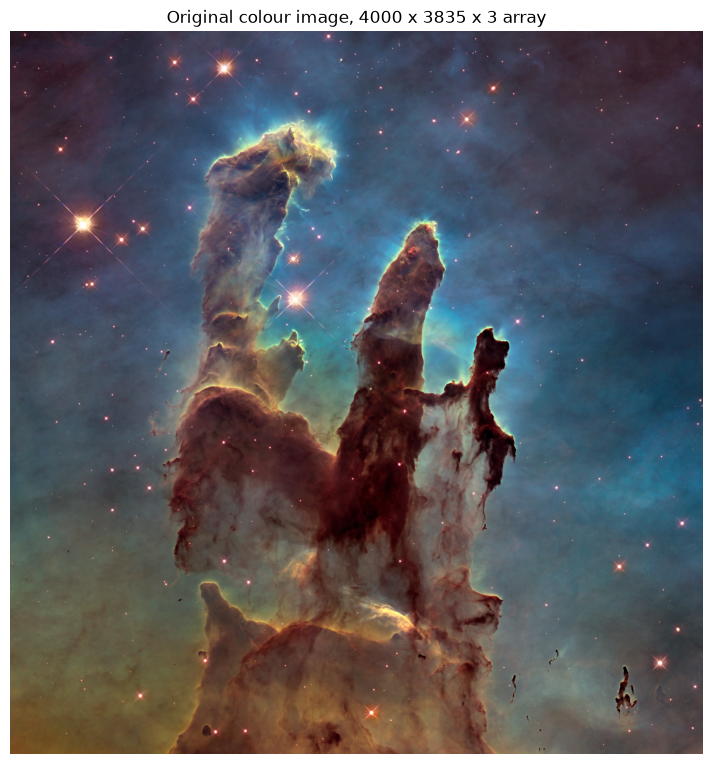

In [ ]:
color_full, color_file_bytes, color_name = load_image(COLOR_SOURCE, "RGB", scipy.datasets.face)

H0, W0, _ = color_full.shape
print(f"Source           : {color_name}")
print(f"Resolution       : {H0} x {W0} x 3  =  {H0*W0/1e6:.1f} megapixels")
print(f"Raw size         : {H0*W0*3:,} numbers (1 byte each) = {human(H0*W0*3)}")
print(f"File size on disk: {human(color_file_bytes)}  (JPEG, already compressed)")

img = shrink(color_full, MAX_SIDE).astype(float)
H, W, _ = img.shape
if (H, W) != (H0, W0):
    print(f"\nWorking copy shrunk to {H} x {W} x 3.  Raw size of working copy: {human(H*W*3)}")

plt.figure(figsize=(9, 9 * H / W))
plt.imshow(to_uint8(img)); plt.axis("off")
plt.title(f"Original colour image, {H} x {W} x 3 array")
plt.show()

### 2.2 Per-channel SVD
Exactly as with CIFAR-100: three $H \times W$ matrices, three SVDs, truncate each to rank $k$, stack back.

Three SVDs took 23.3 s


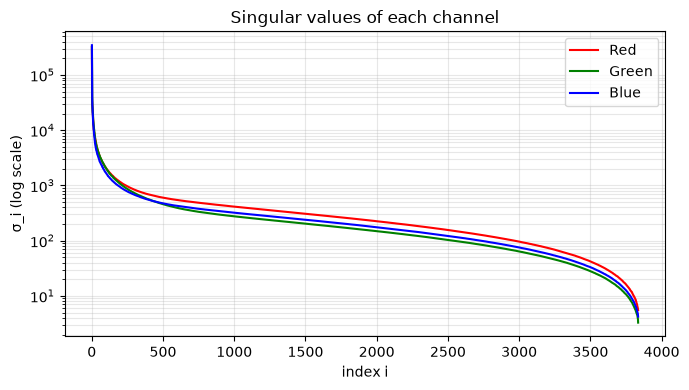

In [ ]:
t0 = time.time()
svds = [np.linalg.svd(img[:, :, c], full_matrices=False) for c in range(3)]
print(f"Three SVDs took {time.time()-t0:.1f} s")

plt.figure(figsize=(7, 4))
for (Uc, sc, Vtc), name, col in zip(svds, ("Red", "Green", "Blue"), ("r", "g", "b")):
    plt.semilogy(np.arange(1, len(sc)+1), sc, color=col, label=name)
plt.xlabel("index i"); plt.ylabel("σ_i (log scale)"); plt.title("Singular values of each channel")
plt.legend(); plt.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.show()

def reconstruct_rgb(svds, k):
    return np.stack([rank_k(Uc, sc, Vtc, k) for (Uc, sc, Vtc) in svds], axis=2)

### 2.3 Reconstruct and compare sizes
Storage is now $3\,k\,(H + W + 1)$ numbers — three channels, each with its own $U_k, s_k, V_k^T$.

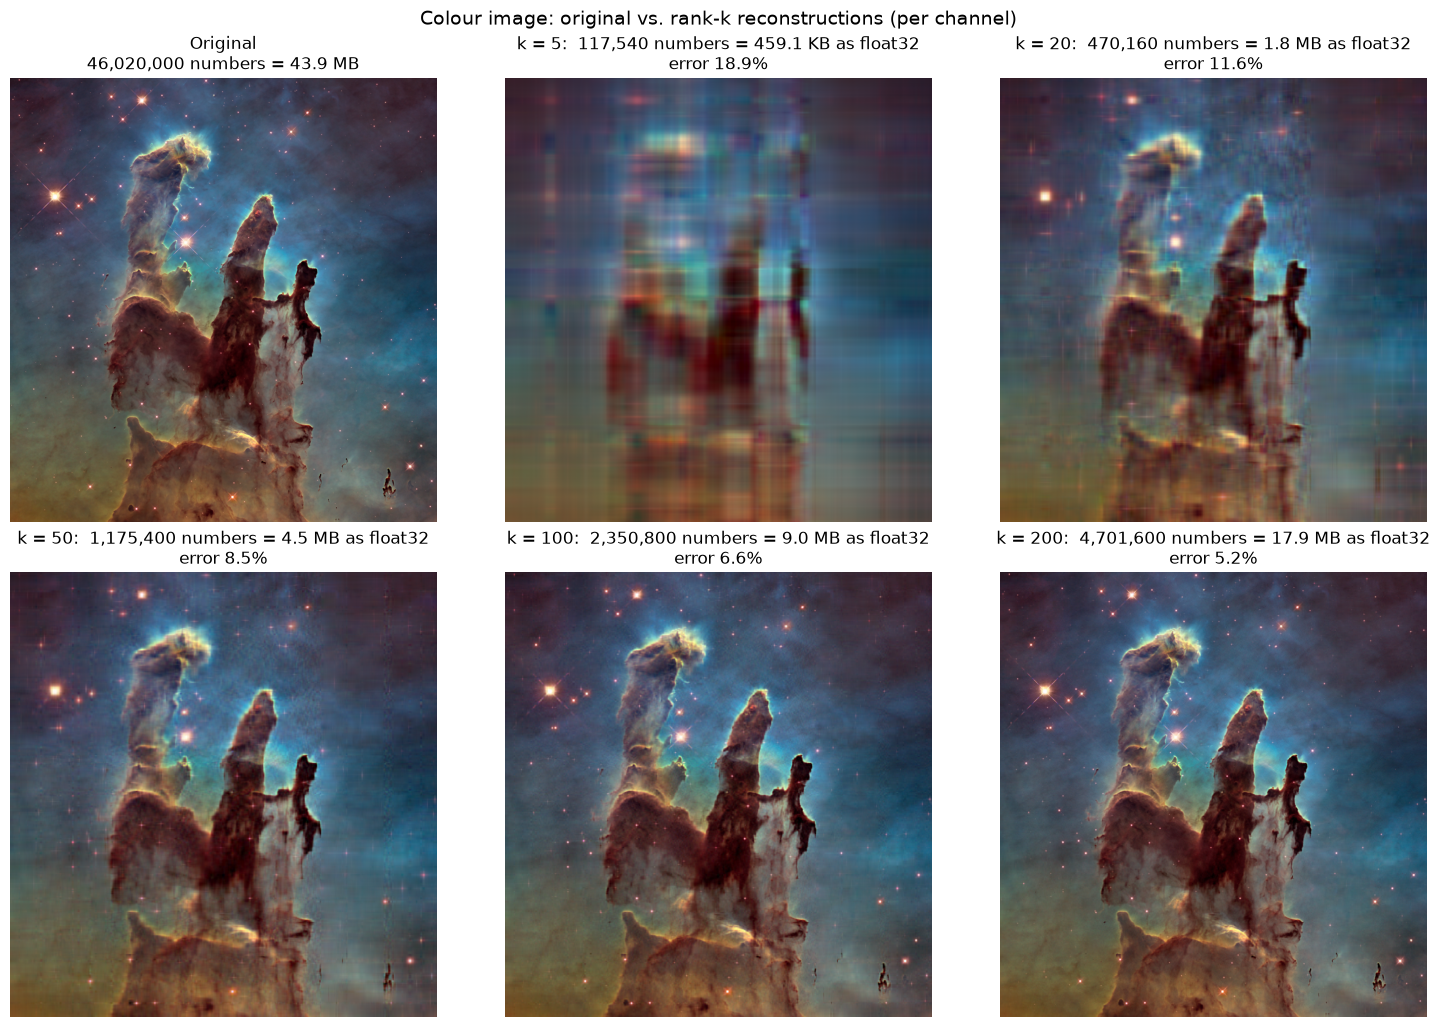

   k | rel. error |  numbers stored | bytes (float32) | orig/SVD
--------------------------------------------------------------------
full |      0.00% |      46,020,000 |         43.9 MB |     1.00
   5 |     18.94% |         117,540 |        459.1 KB |    97.88x
  20 |     11.60% |         470,160 |          1.8 MB |    24.47x
  50 |      8.45% |       1,175,400 |          4.5 MB |     9.79x
 100 |      6.61% |       2,350,800 |          9.0 MB |     4.89x
 200 |      5.21% |       4,701,600 |         17.9 MB |     2.45x


In [ ]:
rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 10 * H / W))
axes = axes.ravel()
axes[0].imshow(to_uint8(img)); axes[0].set_title(f"Original\n{H*W*3:,} numbers = {human(H*W*3)}")
for ax, k in zip(axes[1:], ks):
    img_k = reconstruct_rgb(svds, k)
    err = np.linalg.norm(img - img_k) / np.linalg.norm(img)
    n = svd_storage(H, W, k, 3)
    rows.append((k, err, n, n*4, (H*W*3)/(n*4)))
    ax.imshow(to_uint8(img_k))
    ax.set_title(f"k = {k}:  {n:,} numbers = {human(n*4)} as float32\nerror {err:.1%}")
for ax in axes: ax.axis("off")
plt.suptitle("Colour image: original vs. rank-k reconstructions (per channel)", fontsize=14)
plt.tight_layout(); plt.show()

print(f"{'k':>4} | {'rel. error':>10} | {'numbers stored':>15} | {'bytes (float32)':>15} | {'orig/SVD':>8}")
print("-" * 68)
print(f"{'full':>4} | {0:>10.2%} | {H*W*3:>15,} | {human(H*W*3):>15} | {1:>8.2f}")
for k, err, n, b, ratio in rows:
    print(f"{k:>4} | {err:>10.2%} | {n:>15,} | {human(b):>15} | {ratio:>8.2f}x")

### 2.4 Zoom in

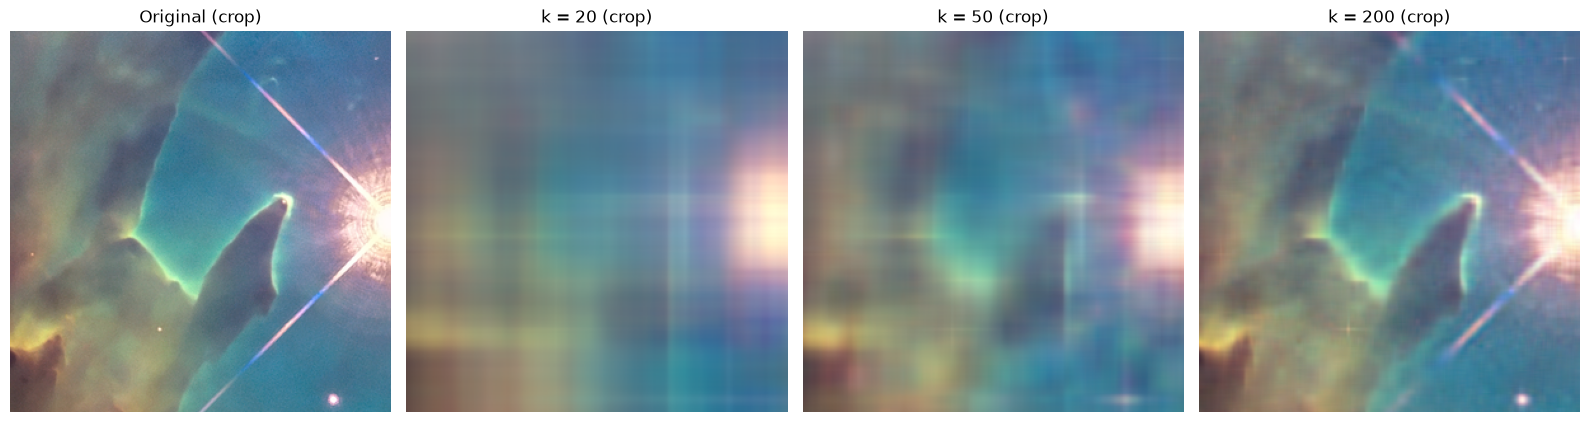

In [ ]:
r0, c0, size = H // 3, W // 3, min(300, H // 3, W // 3)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, k in zip(axes, [None, 20, 50, 200]):
    im = img if k is None else reconstruct_rgb(svds, k)
    ax.imshow(to_uint8(im[r0:r0+size, c0:c0+size])); ax.axis("off")
    ax.set_title("Original (crop)" if k is None else f"k = {k} (crop)")
plt.tight_layout(); plt.show()

## 3. Take-aways for the class

* **Size of the original.** A grayscale image is $H \cdot W$ bytes, a colour image $3 H W$ bytes. A 12-megapixel phone photo is therefore ~36 MB uncompressed, even though the JPEG file is only 3–5 MB.
* **Size after SVD.** Rank-$k$ needs $k(H+W+1)$ numbers per channel. For a $2000 \times 2000$ image, $k = 50$ needs ~200 000 numbers instead of 4 000 000 — a factor of 20 fewer numbers.
* **The catch.** Each stored number is a float, not a byte. With float32 the saving is ×5 rather than ×20; quantising $U_k$ and $V_k$ to 8 bits recovers most of it. JPEG, which exploits local 8 × 8 structure and human vision, still wins at equal quality — SVD is a beautiful *global* low-rank idea, not the best practical codec.
* **Why it works.** Natural images have singular values that decay quickly: a few hundred components capture > 99 % of the energy. What the small singular values carry is fine texture and noise, which is why the reconstructions look slightly soft before they look wrong.